In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
from google.colab import files
from datetime import datetime
from zoneinfo import ZoneInfo
import os

In [ ]:
zona_local = ZoneInfo("Europe/Madrid")
ahora = datetime.now(zona_local).strftime("%Y-%m-%d_%H-%M")
columnas_catalogo = {'SKU', 'Producto en la web', 'PVP'}
columnas_recuento = {'Tienda', 'Fecha del recuento', 'SKU', 'Producto', 'Añada declarada'}
check = False
while not check:
  print("Introduce el  archivo CSV del Catálogo Web:")
  uploaded = files.upload()
  file_name_1 = next(iter(uploaded))
  if file_name_1.lower().endswith(".csv"):
    df_catalogo = pd.read_csv(file_name_1)
    df_catalogo.columns = df_catalogo.columns.str.strip()
    if columnas_catalogo.issubset(set(df_catalogo.columns)):
      check = True
      print("Archivos cargados:", file_name_1)
      print("")
    else:
      print("Archivo cargado no válido.")
      print("")
  else:
    print("Archivo cargado no válido. Por favor, introduce un archivo csv.")
    print("")
check = False
while not check:
  print("Introduce el archivo CSV del Recuento en Tiendas:")
  uploaded = files.upload()
  file_name_2 = next(iter(uploaded))
  if file_name_2.lower().endswith(".csv"):
    df_recuento = pd.read_csv(file_name_2)
    df_recuento.columns = df_recuento.columns.str.strip()
    if columnas_recuento.issubset(set(df_recuento.columns)):
      check = True
      print("Archivos cargados:", file_name_2)
      print("")
    else:
      print("Archivo cargado no válido.")
      print("")
  else:
    print("Archivo cargado no válido. Por favor, introduce un archivo csv.")
    print("")
print("Los archivos son correctos y han sido cargados correctamente")

Introduce el  archivo CSV del Catálogo Web:


Saving catalogo-web-muestra.csv to catalogo-web-muestra (2).csv
Archivos cargados: catalogo-web-muestra (2).csv

Introduce el archivo CSV del Recuento en Tiendas:


Saving 19bf7b2e1db340f3ba230d0cf68a3314.jpg to 19bf7b2e1db340f3ba230d0cf68a3314.jpg
Archivo cargado no válido. Por favor, introduce un archivo csv.

Introduce el archivo CSV del Recuento en Tiendas:


Saving recuento-tiendas-muestra.csv to recuento-tiendas-muestra (3).csv
Archivos cargados: recuento-tiendas-muestra (3).csv

Los archivos son correctos y han sido cargados correctamente


In [ ]:
# Juntar los Data Frames por la columna "SKU"
df_catalogo['SKU'] = df_catalogo['SKU'].astype(str)
df_recuento['SKU'] = df_recuento['SKU'].astype(str)

df = pd.merge(df_catalogo, df_recuento, on = "SKU", how="left")

In [ ]:
# Función auxiliar para aplicar .strip() a elementos de una lista.
def strip_list(list):
  new_list = []
  for l in list:
    new_l = l.strip()
    new_list.append(new_l)
  return new_list

In [ ]:
# Función auxiliar convertir mes num a mes con nombre
def num_mes(num):
  meses =  ["Enero", "Febrero", "Marzo", "Abril", "Mayo", "Junio", "Julio", "Agosto", "Septiembre", "Octubre", "Noviembre", "Diciembre"]
  if np.isnan(num):
    return np.nan
  return meses[int(num)-1]

In [ ]:
# Función auxiliar extraer último dato
def get_year(item):
  return item.split(" ")[-1]

In [ ]:
# Función auxiliar combrobar si un año está en una lista
def year_in_list(row):
  if (row["Año Producto"] in row["Añada declarada"]) and (row["Año Producto en la web"] in row["Añada declarada"]):
    return (True, True)
  elif (row["Año Producto"] in row["Añada declarada"]) and not (row["Año Producto en la web"] in row["Añada declarada"]):
    return (True, False)
  elif not (row["Año Producto"] in row["Añada declarada"]) and (row["Año Producto en la web"] in row["Añada declarada"]):
    return (False, True)
  else:
    return (False, False)

In [ ]:
# Función auxiliar para saber si dos columnas son biyectivas
def one_to_one(col1, col2):
  return len(df[[col1, col2]].drop_duplicates()) == df[col1].nunique() == df[col2].nunique()

In [ ]:
def clasificacion(row):
  if not row.isna().any():
    if row["Año Producto / Añada"] and row["Año Producto en la web / Añada"] and row["Año Producto / Año Producto en la web"]:
      return "Sin discrepancia"
    else:
      return "Con discrepancia"
  else:
    return "Sin recuento en tienda"

In [ ]:
def action(row):
  if row["Clasificación"] == "Sin discrepancia":
    return "OK"
  elif row["Clasificación"] == "Con discrepancia":
    return "Actualizar añada en CMS Web"
  else:
    return "Sin recuento en tienda: Auditar stock físico en almacén"

In [ ]:
# Limpieza de datos
df = df.fillna(np.nan)
df["Fecha del recuento"] = pd.to_datetime(df["Fecha del recuento"])
df["Mes del recuento"] = df["Fecha del recuento"].dt.month.apply(num_mes)
df["Producto en la web"] = df["Producto en la web"].astype(str).str.strip()
df["Tienda"] = df["Tienda"].astype(str).str.strip().fillna(np.nan)
df["Producto"] = df["Producto"].astype(str).str.strip()
df["Añada declarada"] = df["Añada declarada"].astype(str).str.split("+").apply(strip_list)

In [ ]:
# Extraer los años declarados en Producto y en Producto en la web
df["Año Producto"] = df['Producto'].apply(get_year)
df["Año Producto en la web"] = df['Producto en la web'].apply(get_year)
df["Año Producto / Añada"] = df.apply(year_in_list, axis=1).str[0]
df["Año Producto en la web / Añada"] = df.apply(year_in_list, axis=1).str[1]
df["Año Producto / Año Producto en la web"] = False
df.loc[df["Año Producto"] == df["Año Producto en la web"], "Año Producto / Año Producto en la web"] = True

In [ ]:
df["Clasificación"] = df.apply(clasificacion, axis=1)
df["Acción Requerida"] = df.apply(action, axis=1)

In [ ]:
total = df["SKU"].count()
Clasificaciones = ["Con discrepancia", "Sin discrepancia", "Sin recuento en tienda"]
Tiendas = df["Tienda"].unique()
df_clasificacion = pd.DataFrame({
    "Con discrepancia": df[df["Clasificación"]=="Con discrepancia"].count(),
    "Sin discrepancia": df[df["Clasificación"]=="Sin discrepancia"].count(),
    "Sin recuento en tienda": df[df["Clasificación"]=="Sin recuento en tienda"].count()
})
df_clasificacion_count = df_clasificacion.loc["SKU"]

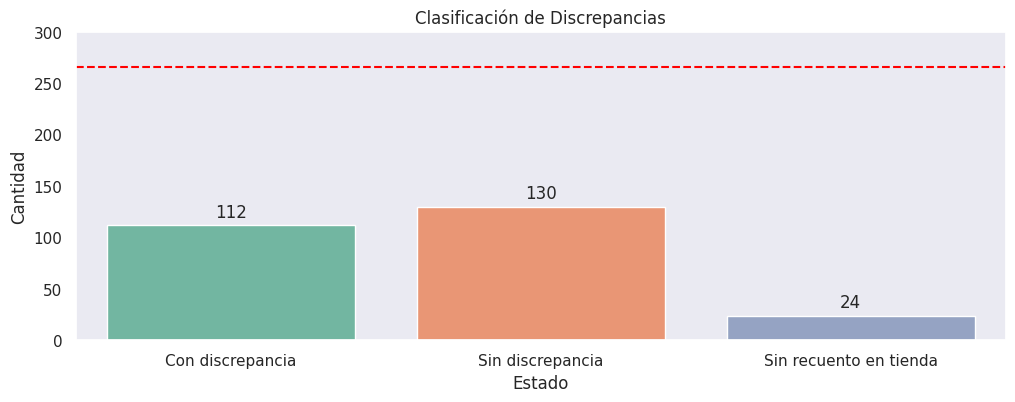

In [ ]:
sns.set_theme(style="dark")
fig, ax = plt.subplots(figsize=(12,4))
sns.barplot(x = Clasificaciones,
            y = [df_clasificacion_count["Con discrepancia"], df_clasificacion_count["Sin discrepancia"], df_clasificacion_count["Sin recuento en tienda"]],
            hue = Clasificaciones,
            palette = "Set2",
            ax=ax)
ax.set_title("Clasificación de Discrepancias")
ax.set_xlabel("Estado")
ax.set_ylabel("Cantidad")
ax.set_ylim(0, 300)
plt.axhline(total, color="red", linestyle="--")
for container in ax.containers:
  ax.bar_label(container, padding=3)
plt.savefig(f"Gráfica - Clasificación de Discrepancias {ahora}.png", dpi=300, bbox_inches='tight')
plt.show()

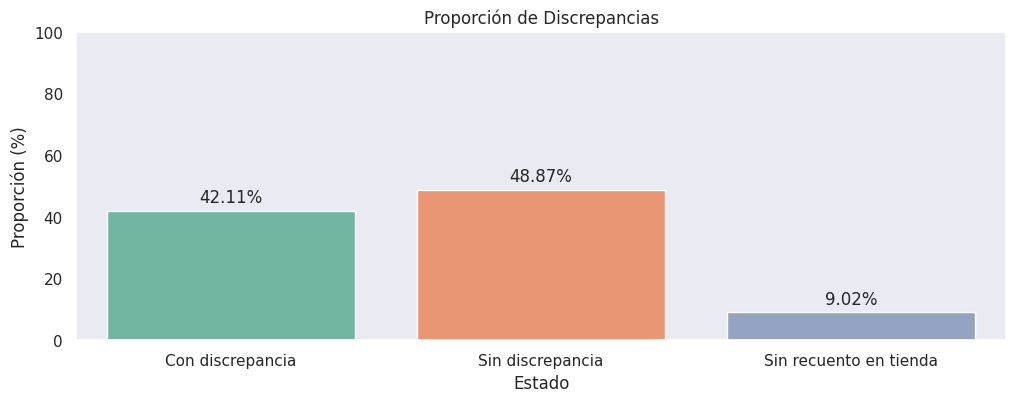

In [ ]:
sns.set_theme(style="dark")
fig, ax = plt.subplots(figsize=(12,4))
sns.barplot(x = Clasificaciones,
            y = [((df_clasificacion_count["Con discrepancia"]/total)*100).round(2), ((df_clasificacion_count["Sin discrepancia"]/total)*100).round(2), ((df_clasificacion_count["Sin recuento en tienda"]/total)*100).round(2)],
            hue = Clasificaciones,
            palette = "Set2",
            ax=ax)
ax.set_title("Proporción de Discrepancias")
ax.set_xlabel("Estado")
ax.set_ylabel("Proporción (%)")
ax.set_ylim(0, 100)
for container in ax.containers:
  ax.bar_label(container, padding=3, fmt="%.2f%%")
plt.savefig(f"Gráfica - Proporción de Discrepancias {ahora}.png", dpi=300, bbox_inches='tight')
plt.show()

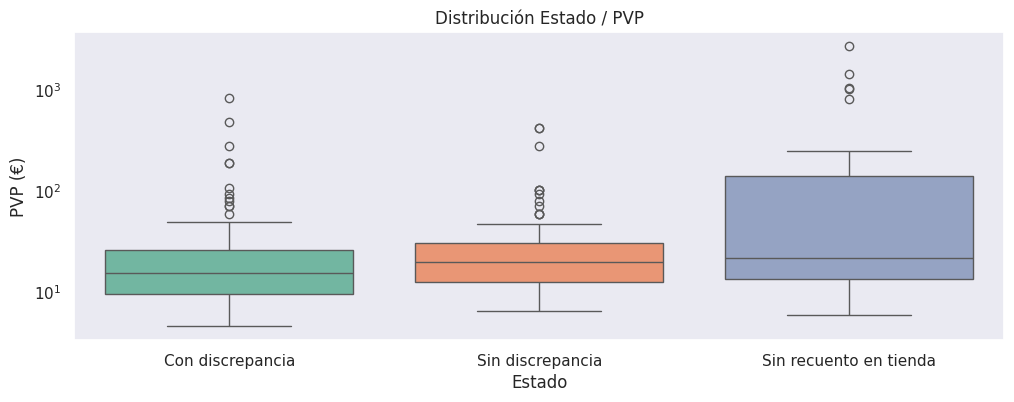

In [ ]:
sns.set_theme(style="dark")
fig, ax = plt.subplots(figsize=(12,4))
sns.boxplot(
    df,
    x = df["Clasificación"],
    y = df["PVP"],
    hue = df["Clasificación"],
    palette="Set2",
    )
plt.yscale("log")
ax.set_title("Distribución Estado / PVP")
ax.set_xlabel("Estado")
ax.set_ylabel("PVP (€)")
plt.savefig(f"Gráfica - Distribución Estado-PVP {ahora}.png", dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
df_ordenado = df.sort_values("PVP", ascending=False, na_position="last")
df_con_discrepancia = df_ordenado[df_ordenado["Clasificación"]=="Con discrepancia"]
df_con_discrepancia_10 = df_con_discrepancia.iloc[0:12]
df_sin_recuento = df_ordenado[df_ordenado["Clasificación"]=="Sin recuento en tienda"]
df_sin_recuento_10 = df_sin_recuento.iloc[0:10]
df_con_problema = df_ordenado[df_ordenado["Clasificación"].isin(["Con discrepancia", "Sin recuento en tienda"])]
df_casos_arreglar_primero = df_con_problema[0:10]

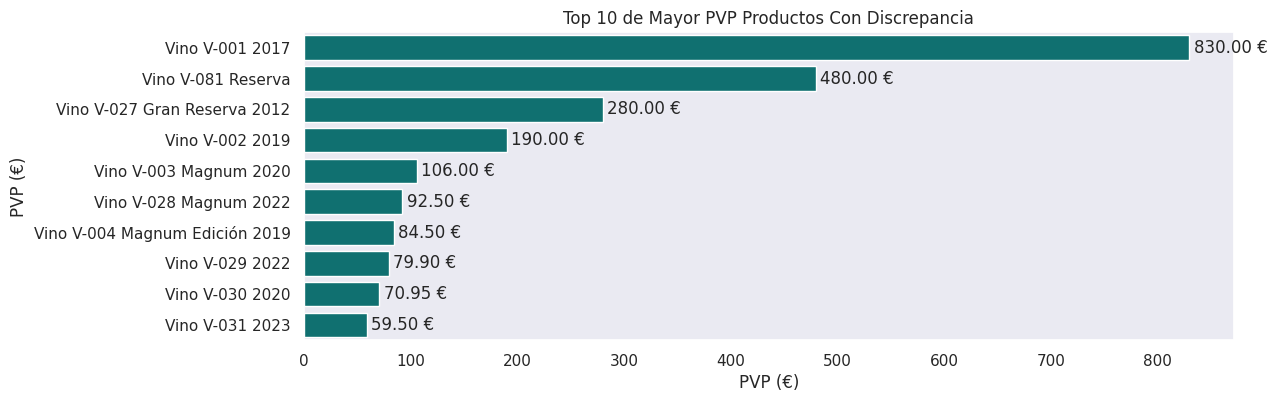

In [ ]:
sns.set_theme(style="dark")
fig, ax = plt.subplots(figsize=(12,4))
sns.barplot(df_con_discrepancia_10, x="PVP", y="Producto en la web", color = "teal", ax=ax)
ax.set_title("Top 10 de Mayor PVP Productos Con Discrepancia")
ax.set_xlabel("PVP (€)")
ax.set_ylabel("Producto")
for container in ax.containers:
  ax.bar_label(container, padding=3, fmt='{:,.2f} €')
ax.set_ylabel("PVP (€)")
plt.savefig(f"Gráfica - Top 10 de Mayor PVP Productos Con Discrepancia {ahora}.png", dpi=300, bbox_inches='tight')
plt.show()

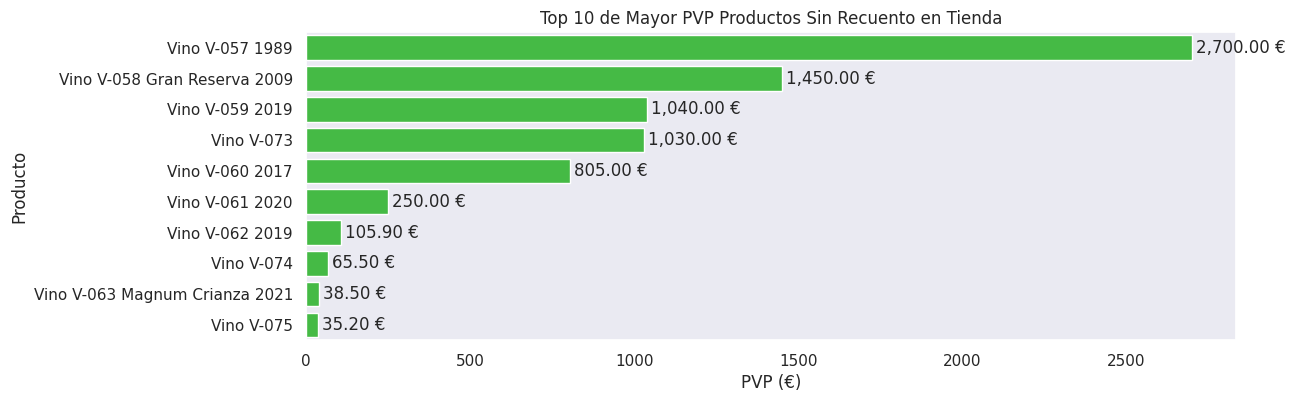

In [ ]:
sns.set_theme(style="dark")
fig, ax = plt.subplots(figsize=(12,4))
sns.barplot(df_sin_recuento_10, x="PVP", y="Producto en la web", color = "limegreen", ax=ax)
ax.set_title("Top 10 de Mayor PVP Productos Sin Recuento en Tienda")
ax.set_xlabel("PVP (€)")
ax.set_ylabel("Producto")
for container in ax.containers:
  ax.bar_label(container, padding=3, fmt='{:,.2f} €')
plt.savefig(f"Gráfica - Top 10 de Mayor PVP Productos Sin Recuento en Tienda {ahora}.png", dpi=300, bbox_inches='tight')
plt.show()

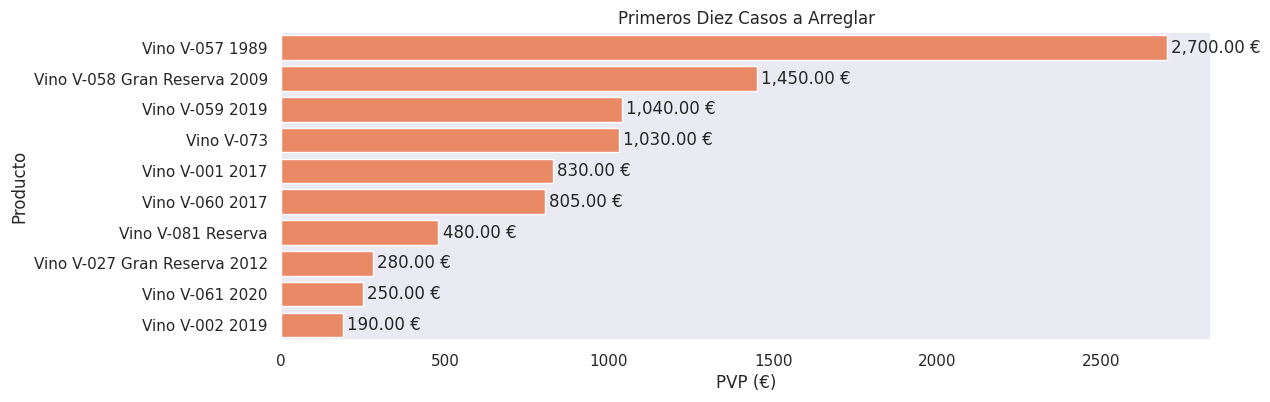

In [ ]:
sns.set_theme(style="dark")
fig, ax = plt.subplots(figsize=(12, 4))
sns.barplot(df_casos_arreglar_primero, x="PVP", y="Producto en la web", color="coral", ax=ax)
ax.set_title("Primeros Diez Casos a Arreglar")
ax.set_xlabel("PVP (€)")
ax.set_ylabel("Producto")
for container in ax.containers:
  ax.bar_label(container, padding=3, fmt='{:,.2f} €')
plt.savefig(f"Gráfica - Primeros Diez Casos a Arreglar {ahora}.png", dpi=300, bbox_inches='tight')
plt.show()

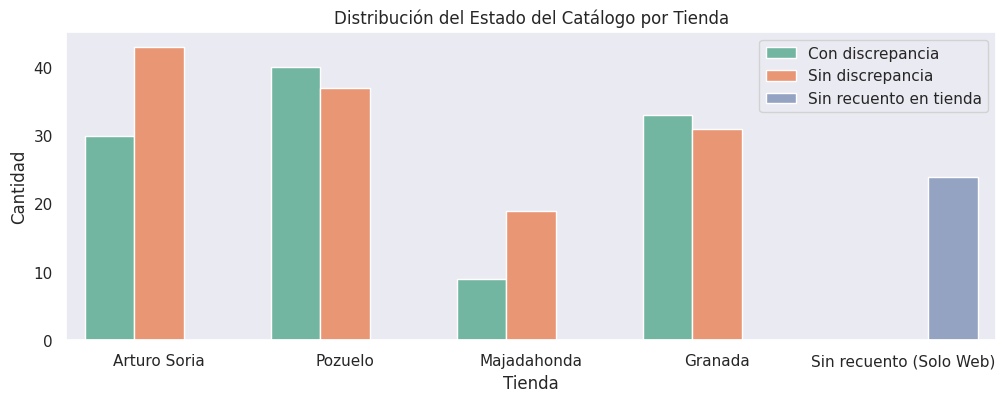

In [ ]:
sns.set_theme(style="dark")
fig, ax = plt.subplots(figsize=(12,4))
df_plot = df.copy()
df_plot["Tienda"] = (
    df_plot["Tienda"].astype(str).replace({"nan": "Sin recuento (Solo Web)"})
)
sns.countplot(
    data=df_plot, x="Tienda", hue="Clasificación", palette="Set2", ax=ax
)
ax.set_title("Distribución del Estado del Catálogo por Tienda")
ax.set_xlabel("Tienda")
ax.set_ylabel("Cantidad")
ax.legend()
plt.savefig(f"Gráfica - Distribución del Estado del Catálogo por Tienda {ahora}.png", dpi=300, bbox_inches='tight')
plt.show()

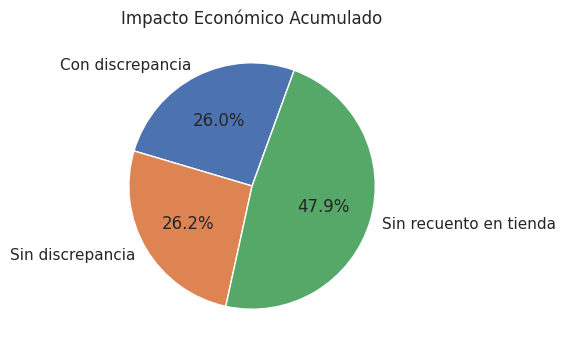

In [ ]:
from matplotlib import legend
df_PVP_clasificacion = df.groupby("Clasificación")["PVP"].sum()
PVP_clasificacion = [df_PVP_clasificacion.get("Con discrepancia", 0),df_PVP_clasificacion.get("Sin discrepancia", 0),df_PVP_clasificacion.get("Sin recuento en tienda", 0)]
fig, ax = plt.subplots(figsize=(4, 4))
ax.pie(PVP_clasificacion, labels=Clasificaciones, autopct='%1.1f%%', startangle=70)
ax.set_title("Impacto Económico Acumulado")
plt.savefig(f"Gráfica - Impacto Económico Acumulado {ahora}.png", dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
texto = {
    "Título": "=== INFORME DE DIAGNÓSTICO Y AUDITORÍA DE CATÁLOGO ===",
    "Ok": "OK: El producto y la añada coinciden perfectamente entre el catálogo web y la tienda.",
    "Discrepancia_añada": (
        "Discrepancia detectada en la añada. La añada del catálogo web no"
        " coincide con el recuento físico de la tienda. Requiere actualización"
        " en el CMS Web."
    ),
    "Discrepancia_nombre": (
        "Discrepancia detectada en el nombre del producto. Existe una"
        " diferencia en la nomenclatura entre la web y la tienda."
    ),
    "Discrepancia_general": (
        "Discrepancia en los datos del producto. Se recomienda revisar la"
        " ficha en el CMS Web y el etiquetado en tienda."
    ),
    "Sin_Recuento": (
        "Sin recuento en tienda. El producto está dado de alta en la web pero"
        " no figura en el inventario físico. Se requiere auditar el stock en"
        " almacén."
    )
}


In [ ]:
lineas_txt = []
lineas_txt.append(texto["Título"])
lineas_txt.append(f"Fecha de generación: {ahora}\n")
lineas_txt.append("-" * 75 + "\n")

df_unicos = df.drop_duplicates(
    subset=["SKU", "Tienda", "Producto en la web", "Clasificación"]
)

for idx, row in df_unicos.iterrows():
  sku = row["SKU"]
  producto = row["Producto en la web"]
  tienda = (
      row["Tienda"]
      if pd.notna(row["Tienda"]) and str(row["Tienda"]) != "nan"
      else "Sin Tienda (Solo Web)"
  )
  clasif = row["Clasificación"]

  prefix = f"[{sku}] [{tienda}] {producto}"

  if clasif == "Sin discrepancia":
    lineas_txt.append(f"{prefix}: {texto['Ok']}")
  elif clasif == "Con discrepancia":
    lineas_txt.append(f"{prefix}: {texto['Discrepancia_añada']}")
  elif clasif == "Sin recuento en tienda":
    lineas_txt.append(f"{prefix}: {texto['Sin_Recuento']}")

nombre_txt = f"Informe de Diagnóstico y Auditoría de Catálogo {ahora}.txt"
with open(nombre_txt, "w", encoding="utf-8") as f:
  f.write("\n".join(lineas_txt))

In [ ]:
df_final = df.sort_values(
    by="PVP", ascending=False, na_position="last"
).reset_index(drop=True)

df_final.to_csv(f"CSV Recuento en Tiendas y Catálogo Web Cruzado y Procesado {ahora}.csv", index=False)

archivos_zip = [
    f"Gráfica - Clasificación de Discrepancias {ahora}.png",
    f"Gráfica - Proporción de Discrepancias {ahora}.png",
    f"Gráfica - Distribución Estado-PVP {ahora}.png",
    f"Gráfica - Top 10 de Mayor PVP Productos Con Discrepancia {ahora}.png",
    f"Gráfica - Top 10 de Mayor PVP Productos Sin Recuento en Tienda {ahora}.png",
    f"Gráfica - Primeros Diez Casos a Arreglar {ahora}.png",
    f"Gráfica - Distribución del Estado del Catálogo por Tienda {ahora}.png",
    f"Gráfica - Impacto Económico Acumulado {ahora}.png",
    f"CSV Recuento en Tiendas y Catálogo Web Cruzado y Procesado {ahora}.csv",
    f"Informe de Diagnóstico y Auditoría de Catálogo {ahora}.txt"
]

with zipfile.ZipFile(f"Reporte_Discrepancias {ahora}.zip", "w") as zipf:
  for archivo in archivos_zip:
    if os.path.exists(archivo):
      zipf.write(archivo)

files.download(f"Reporte_Discrepancias {ahora}.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>